In [4]:
ls

Analyser.ipynb           test_eval_service_10/    test_eval_service_3/
gap_boxplots_multik.pdf  test_eval_service_12/    test_eval_service_5/
gap_boxplots_multik.png  test_eval_service_14/    test_eval_service_8/


In [1]:
import pandas as pd
import numpy as np

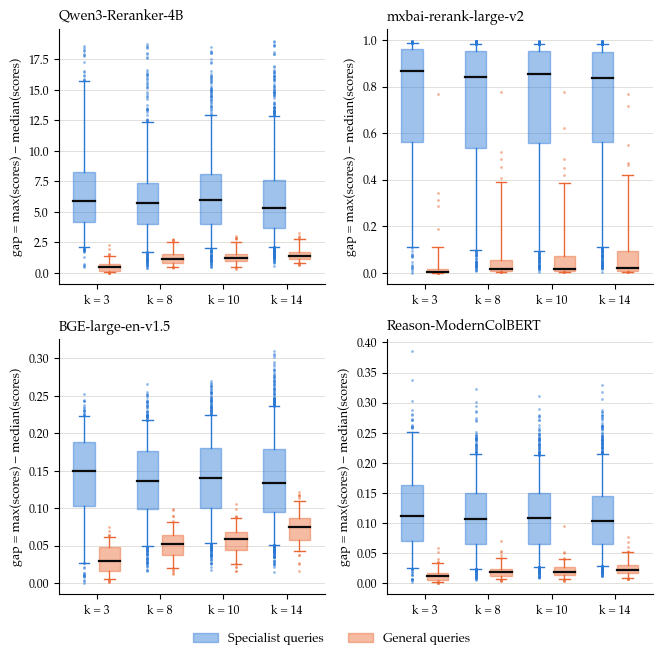

In [8]:
from pathlib import Path
import logging
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch

logging.getLogger("fontTools.subset").setLevel(logging.ERROR)   # hides the font warnings

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Palatino Linotype", "Palatino", "TeX Gyre Pagella", "P052",
                   "URW Palladio L", "Book Antiqua", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

BASE = Path(".")                     # the notebook's own folder (cleaned_data)
KS = [3, 8, 10,14]           # folders test_eval_service_<k>

FILES = {
    "Qwen3-Reranker-4B":     "cross-encoder_Qwen-Qwen3-Reranker-4B_cleaned.csv",
    "mxbai-rerank-large-v2": "cross-encoder_mixedbread-ai-mxbai-rerank-large-v2_cleaned.csv",
    "BGE-large-en-v1.5":     "bi-encoder_BAAI-bge-large-en-v1.5_cleaned.csv",
    "Reason-ModernColBERT":  "colbert_lightonai-Reason-ModernColBERT_cleaned.csv",
}

def load_gap(path):
    d = pd.read_csv(path)
    S = d[[c for c in d.columns if c.endswith("_scores")]].to_numpy(dtype=float)
    g = S.max(axis=1) - np.median(S, axis=1)                 # gap = max - median
    spec = (d["expected_service"] != "general").to_numpy()   # True = specialist query
    return S.shape[1], g, spec

BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#e1e0d9"

fig, axes = plt.subplots(2, 2, figsize=(6.7, 6.6), facecolor="white")
for ax, (title, fname) in zip(axes.ravel(), FILES.items()):
    ticks = []
    for k in KS:
        path = BASE / f"test_eval_service_{k}" / fname
        if not path.exists():
            print("missing:", path)
            continue
        kk, g, spec = load_gap(path)
        pos = len(ticks)
        for off, data, col in ((-0.2, g[spec], BLUE), (0.2, g[~spec], ORANGE)):
            ax.boxplot(data, positions=[pos + off], widths=0.34, patch_artist=True,
                       whis=(5, 95), zorder=3,
                       flierprops=dict(marker="o", ms=2, mfc=col, mec="none", alpha=.5),
                       medianprops=dict(color=INK, lw=1.6),
                       whiskerprops=dict(color=col, lw=1), capprops=dict(color=col, lw=1),
                       boxprops=dict(facecolor=col, alpha=.45, edgecolor=col, lw=1))
        ticks.append(f"k = {kk}")

    ax.set_xticks(range(len(ticks))); ax.set_xticklabels(ticks)
    ax.set_xlim(-0.6, len(ticks) - 0.4)
    ax.set_ylabel("gap = max(scores) − median(scores)")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="y", color=GRID, lw=.7); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)

fig.legend(handles=[Patch(fc=BLUE, alpha=.45, ec=BLUE, label="Specialist queries"),
                    Patch(fc=ORANGE, alpha=.45, ec=ORANGE, label="General queries")],
           loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(.5, 0))
fig.tight_layout(rect=(0, .04, 1, 1))
fig.savefig("gap_boxplots_multik.pdf", bbox_inches="tight", facecolor="white")
fig.savefig("gap_boxplots_multik.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()